# Geometry-Aware Quantum Cloud Challenge — Submission

**Team:** QCCR  
**Members:** Clement, Wright, Raymond Zhang  
**Repository / commit:** https://github.com/Clement-Wright/Geometry-Aware-Quantum-Cloud-Challenge-QCCR.git / Level 1 implementation 

Complete Levels 1–3 for all three official processor models. Read the challenge brief and practice tutorial first. Load the shared inputs from `challenge_config.py`; keep the official benchmark separate from optional studies. All solution code and results are yours to supply.

Success means a reproducible comparison of routing and protection tradeoffs across all nine cases. Protection need not improve fidelity, and the hyperbolic model need not win. Explain negative results using your measured costs, uncertainty and yield. All required runs are local simulations; no IBM account or QPU access is needed.


## Setup and reproducibility

Record package versions, simulator and transpiler seeds, shots **per basis**, bootstrap settings, optimization level, layout and routing settings. Use independent simulator seeds for XX, YY and ZZ. Explain any differences in compilation between models. Start Jupyter from this repository with `uv run jupyter lab challenge_submission.ipynb`.


In [5]:
import platform
from importlib.metadata import version

import importlib.metadata as md
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, partial_trace, state_fidelity
from qiskit.transpiler.passes import RemoveBarriers
from qiskit_aer import AerSimulator

import challenge_config as cfg
from challenge_config import (
    BOOTSTRAP_RESAMPLES, CASES, CONFIDENCE_LEVEL, CONFIG_VERSION, PROCESSORS,
    SEED, SHOTS_PER_BASIS, SYNTHETIC_BASIS_GATES, get_ibm_backend, make_noise_model,
)

CASE_NUMBER = 1
BASIS_ORDER = ("XX", "YY", "ZZ")
SIMULATOR_METHOD = "matrix_product_state"
OPTIMIZATION_LEVEL = 0
processor_id = "reference_2016"
spec = PROCESSORS[processor_id]
case1_simulator_seeds = {
    basis: SEED + 100 * CASE_NUMBER + index
    for index, basis in enumerate(BASIS_ORDER)
}
case1_bootstrap_seed = SEED + 100 * CASE_NUMBER + 10
case1_settings = {
    "Case": CASE_NUMBER,
    "Processor": processor_id,
    "Configuration version": CONFIG_VERSION,
    "Physical ports": spec.ports,
    "Noise": "off",
    "Native basis": SYNTHETIC_BASIS_GATES,
    "Simulator method": SIMULATOR_METHOD,
    "Shots per basis": SHOTS_PER_BASIS,
    "Simulator seeds": case1_simulator_seeds,
    "Transpiler seed": SEED,
    "Initial layout": list(range(spec.num_qubits)),
    "Routing method": "none (explicit SWAPs already supplied)",
    "Optimization level": OPTIMIZATION_LEVEL,
    "Bootstrap resamples": BOOTSTRAP_RESAMPLES,
    "Confidence level": CONFIDENCE_LEVEL,
    "Bootstrap seed": case1_bootstrap_seed,
}
display(pd.Series(case1_settings, name="Value").to_frame())
display(pd.DataFrame([
    {"Package": "Python", "Version": platform.python_version()},
    *({"Package": package, "Version": version(package)}
      for package in ("qiskit", "qiskit-aer", "qiskit-ibm-runtime")),
]))

BASIS_ORDER = ("XX", "YY", "ZZ")
LEVEL2_CASES = tuple(case for case in CASES if case[2] == 2)
SIMULATOR_METHOD = "matrix_product_state"
OPTIMIZATION_LEVEL = 0
SIMULATOR_OPTIONS = {
    "reference_2016": {},
    "ibm_today": {"max_parallel_threads": 1, "max_parallel_experiments": 1,
                  "matrix_product_state_truncation_threshold": 1e-16,
                  "mps_sample_measure_algorithm": "mps_apply_measure"},
    "hyperbolic": {"max_parallel_threads": 1},
}

# MPS stores the 35-qubit state as a chain of smaller tensors.
# Record its sampling options alongside the seeds for repeatability.
run_settings = {
    "Configuration version": CONFIG_VERSION,
    "Cases": [case_number for case_number, _, _ in LEVEL2_CASES],
    "Noise": "official Level 2 model",
    "Simulator method": SIMULATOR_METHOD, "Simulator options": SIMULATOR_OPTIONS,
    "Shots per basis": SHOTS_PER_BASIS, "Base seed": SEED,
    "Simulator seed rule": "base + 100 * case + basis index (XX=0, YY=1, ZZ=2)",
    "Transpiler seed": SEED, "Optimization level": OPTIMIZATION_LEVEL,
    "Layout": "identity physical layout", "Routing": "explicit SWAPs; automatic routing off",
    "Bootstrap resamples": BOOTSTRAP_RESAMPLES, "Confidence level": CONFIDENCE_LEVEL,
    "Bootstrap seed rule": "base + 100 * case + 10",
}
display(pd.Series(run_settings, name="Value").to_frame())
display(pd.DataFrame([
    {"Package": "Python", "Version": platform.python_version()},
    *({"Package": package, "Version": version(package)} for package in
      ("qiskit", "qiskit-aer", "qiskit-ibm-runtime", "numpy", "networkx", "pandas", "matplotlib")),
]))

# Load IBM FakeGuadalupeV2 backend
ibm_backend = get_ibm_backend()
ibm_backend_record = {
    "Backend": ibm_backend.name,
    "Class": f"{type(ibm_backend).__module__}.{type(ibm_backend).__name__}",
    "Snapshot update": str(ibm_backend.properties().last_update_date),
    "Target operations": sorted(ibm_backend.operation_names),
}
display(pd.Series(ibm_backend_record, name="Value").to_frame())

,Value
Case,1
Processor,reference_2016
Configuration version,1.0
Physical ports,"(0, 3)"
Noise,off
Native basis,"(u, cx)"
Simulator method,matrix_product_state
Shots per basis,8192
Simulator seeds,"{'XX': 2126, 'YY': 2127, 'ZZ': 2128}"
Transpiler seed,2026


,Package,Version
0,Python,3.12.8
1,qiskit,2.4.1
2,qiskit-aer,0.17.2
3,qiskit-ibm-runtime,0.51.0


,Value
Configuration version,1.0
Cases,"[2, 5, 8]"
Noise,official Level 2 model
Simulator method,matrix_product_state
Simulator options,"{'reference_2016': {}, 'ibm_today': {'max_para..."
Shots per basis,8192
Base seed,2026
Simulator seed rule,"base + 100 * case + basis index (XX=0, YY=1, Z..."
Transpiler seed,2026
Optimization level,0


,Package,Version
0,Python,3.12.8
1,qiskit,2.4.1
2,qiskit-aer,0.17.2
3,qiskit-ibm-runtime,0.51.0
4,numpy,2.5.4
5,networkx,3.7
6,pandas,3.1.0
7,matplotlib,3.11.2


,Value
Backend,fake_guadalupe
Class,qiskit_ibm_runtime.fake_provider.backends.guad...
Snapshot update,2021-04-20 07:26:31+02:00
Target operations,"[cx, delay, id, measure, reset, rz, sx, x]"


## Official graphs and ports

Draw all three coupling graphs, label physical qubits and highlight each fixed port pair. State the noise model and native gates for each processor. For the IBM model, record the exact fake backend and package version. Explain how the final physical locations of the Bell pair will be verified.

Use `challenge_config.PROCESSORS` for the three specs (`edges`, `ports`, `num_qubits`, `coupling_map()`), `CASES` for case numbering, and `get_ibm_backend()` / `make_noise_model(processor_id)` for the fixed backend and noise. See the README for gate bases and sampling defaults. The IBM snapshot is bundled with `qiskit-ibm-runtime==0.51.0`; do not refresh it.


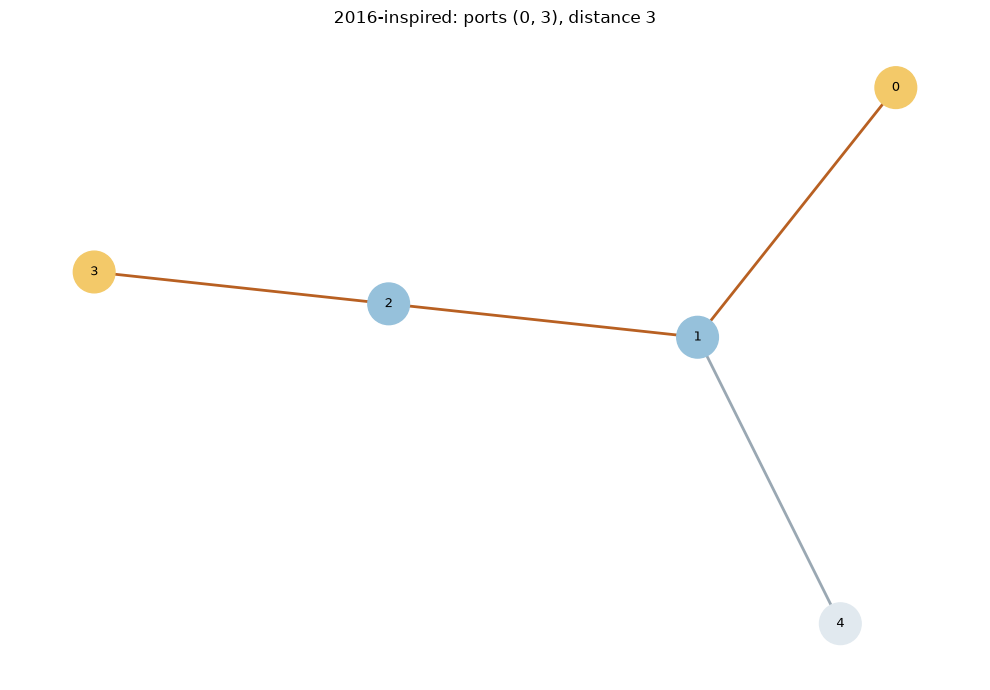

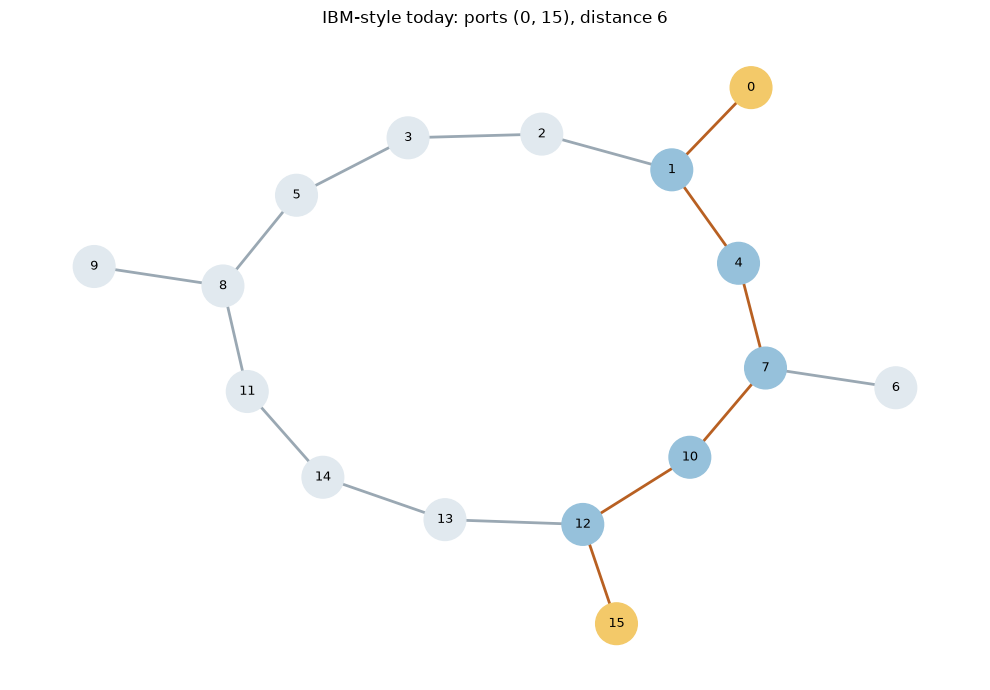

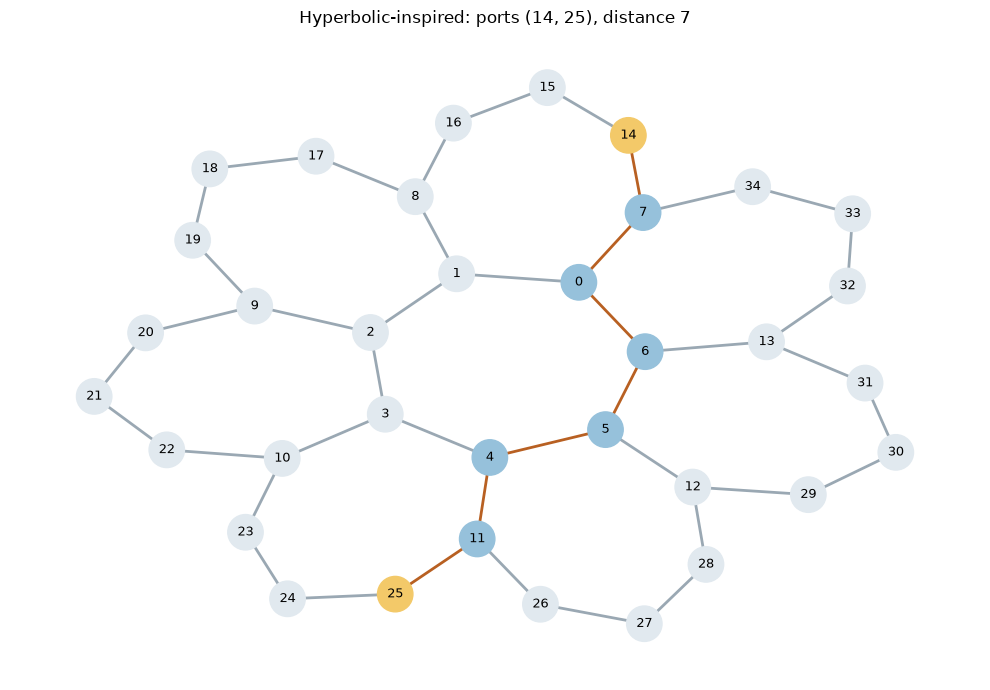

,Processor,Physical ports,Physical qubits,Undirected edges,Route,Port distance
0,reference_2016,"(0, 3)",5,4,"[0, 1, 2, 3]",3
1,ibm_today,"(0, 15)",16,16,"[0, 1, 4, 7, 10, 12, 15]",6
2,hyperbolic,"(14, 25)",35,42,"[14, 7, 0, 6, 5, 4, 11, 25]",7


In [6]:
processor_graphs, processor_routes = {}, {}
graph_rows = []
for model_id, model in PROCESSORS.items():
    graph = nx.Graph()
    graph.add_nodes_from(range(model.num_qubits))
    graph.add_edges_from(model.edges)

    # Draw each bidirectional coupling as one connection between physical qubits.
    # Choose a path with the fewest edges between the fixed ports.
    route = nx.shortest_path(graph, *model.ports)
    processor_graphs[model_id] = graph
    processor_routes[model_id] = route
    graph_rows.append({
        "Processor": model_id, "Physical ports": model.ports,
        "Physical qubits": model.num_qubits, "Undirected edges": graph.number_of_edges(),
        "Route": route, "Port distance": len(route) - 1,
    })
    node_colors = ["#f3c969" if qubit in model.ports else
                   "#96c1db" if qubit in route else "#e1e9ef" for qubit in graph.nodes]
    route_edges = {frozenset(edge) for edge in zip(route, route[1:])}
    edge_colors = ["#b86022" if frozenset(edge) in route_edges else "#9aa8b3"
                   for edge in graph.edges]
    figure, axis = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(
        graph, pos=nx.kamada_kawai_layout(graph), node_color=node_colors,
        edge_color=edge_colors, node_size=650 if model.num_qubits > 20 else 900,
        font_size=9, width=2, ax=axis,
    )
    axis.set_title(f"{model.name}: ports {model.ports}, distance {len(route) - 1}")
    axis.set_axis_off()
    figure.tight_layout()
    display(figure)
    plt.close(figure)

display(pd.DataFrame(graph_rows))

## Level 1 — Make it: an ideal Bell pair

**Cases 1, 4, 7:** 2016-inspired, IBM-style today, hyperbolic-inspired.

Prepare the target Bell state on each model's two fixed ports. Compile for the relevant connectivity and gate set, verify the final physical locations, and draw the transpiled circuits. Measure XX, YY and ZZ without noise and estimate Bell fidelity. Record depth, two-qubit gates, SWAPs before decomposition, and physical qubits actually used. Follow the README common reporting conventions: the table uses the complete ZZ circuit, depth includes measurements with barriers excluded, and two-qubit gates are counted after native-gate decomposition. Preserve the routed circuit to count SWAPs before decomposition. Report XX and YY costs, including their basis rotations, separately.


In [7]:
# ---- Reproducibility record -------------------------------------------------
print("challenge_config", cfg.CONFIG_VERSION, "| IBM backend", cfg.IBM_BACKEND_CLASS)
print({p: md.version(p) for p in ("qiskit", "qiskit-aer", "qiskit-ibm-runtime", "networkx", "numpy")})
print(f"base seed {SEED} | shots per basis {SHOTS_PER_BASIS} | "
      f"bootstrap {BOOTSTRAP_RESAMPLES} resamples, {CONFIDENCE_LEVEL:.0%} interval")

BASES = ("ZZ", "XX", "YY")
TRANSPILE_OPT_LEVEL = 1     # keep <= 1: the tutorial warns levels >= 2 may elide hand-written SWAPs

def case_seed(case, basis, kind):
    """Distinct seed per case and basis. kind: 0 = Aer simulator, 1 = bootstrap."""
    return SEED + 100 * case + 10 * kind + BASES.index(basis)

def transpiler_seed(case):
    return SEED + 100 * case + 20

# ---- Measurement helpers (same conventions as the tutorial) -----------------
def bits(key):
    """Counts key -> string where bits(key)[i] is classical bit i."""
    return key.replace(" ", "")[::-1]

def correlator(counts, i=0, j=1):
    """Mean of (+1 if clbits i and j agree, else -1) over all shots."""
    agree = sum(n for key, n in counts.items() if bits(key)[i] == bits(key)[j])
    return (2 * agree - sum(counts.values())) / sum(counts.values())

def add_basis_rotation(qc, qubits, basis):
    """Append gates so a Z measurement of `qubits` reads the basis named by `basis`
    ("ZZ", "XX", "YY" or a single letter): Z adds nothing, X adds H, Y adds Sdg then H."""
    axis = basis[0]
    if axis not in "XYZ":
        raise ValueError(f"unknown basis {basis!r}")
    for q in qubits:
        if axis == "Y":
            qc.sdg(q)
        if axis in "XY":
            qc.h(q)

def measured_qubits(tqc):
    """{classical bit: physical qubit it measures} for a transpiled circuit."""
    return {tqc.find_bit(i.clbits[0]).index: tqc.find_bit(i.qubits[0]).index
            for i in tqc.data if i.operation.name == "measure"}

# ---- Fidelity with a bootstrap interval -------------------------------------
def fidelity_with_ci(counts_by_basis, case, n_boot=BOOTSTRAP_RESAMPLES, level=CONFIDENCE_LEVEL):
    """F = (1 + <XX> - <YY> + <ZZ>)/4 and its percentile bootstrap interval.

    Each basis is resampled on its own (multinomial resampling of its counts, which is
    equivalent to resampling shots with replacement) with its own seed, and the three
    resampled correlators are combined in every round. Returns (F, lo, hi, correlators).
    """
    point, boot = {}, {}
    for basis in BASES:
        counts = counts_by_basis[basis]
        keys, total = list(counts), sum(counts.values())
        sign = np.array([1 if bits(k)[0] == bits(k)[1] else -1 for k in keys])
        probs = np.array([counts[k] for k in keys]) / total
        rng = np.random.default_rng(case_seed(case, basis, 1))
        boot[basis] = rng.multinomial(total, probs, size=n_boot) @ sign / total
        point[basis] = correlator(counts)
    combine = lambda c: (1 + c["XX"] - c["YY"] + c["ZZ"]) / 4
    tail = 100 * (1 - level) / 2
    lo, hi = np.percentile(combine(boot), [tail, 100 - tail])
    return combine(point), lo, hi, point

# ---- Circuit cost metrics (README reporting conventions) --------------------
def strip_barriers(tqc):
    return RemoveBarriers()(tqc)

def two_qubit_gates(tqc):
    return sum(len(i.qubits) == 2 and i.operation.name != "barrier" for i in tqc.data)

def physical_qubits_used(tqc):
    """Distinct physical qubits touched by non-barrier operations."""
    return {tqc.find_bit(q).index for i in tqc.data if i.operation.name != "barrier" for q in i.qubits}

def circuit_costs(routed, native):
    """Depth incl. measurements (barriers removed), native 2q gates, SWAPs before decomposition."""
    c = strip_barriers(native)
    return {"depth": c.depth(), "two_qubit_gates": two_qubit_gates(c),
            "swaps": routed.count_ops().get("swap", 0), "physical_qubits": len(physical_qubits_used(c))}

# ---- Simulation -------------------------------------------------------------
def run_counts(native, pid, case, basis, noise_model=None):
    """Run one compiled basis circuit on Aer. Use MPS for the 35-qubit graph (README)."""
    method = "matrix_product_state" if pid == "hyperbolic" else "automatic"
    sim = AerSimulator(method=method, noise_model=noise_model, seed_simulator=case_seed(case, basis, 0))
    return sim.run(native, shots=SHOTS_PER_BASIS).result().get_counts()


challenge_config 1.0 | IBM backend qiskit_ibm_runtime.fake_provider.FakeGuadalupeV2
{'qiskit': '2.4.1', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.51.0', 'networkx': '3.7', 'numpy': '2.5.4'}
base seed 2026 | shots per basis 8192 | bootstrap 2000 resamples, 95% interval


In [8]:
# Level 1 compilation: build the Bell circuit on the ports, route by hand, compile to native gates.

def port_path(spec):
    """Deterministic shortest path between the ports (lexicographically first if there are ties)."""
    paths = sorted(nx.all_shortest_paths(nx.Graph(list(spec.edges)), *spec.ports))
    return paths[0], len(paths)

def bell_transport_circuit(path, basis):
    """Virtual qubit i sits on physical qubit path[i]; the circuit is written in that order.

    |Phi+> is made on the middle edge of the path, then each half is walked outward with
    explicit SWAPs until it sits on a port. That is d-1 SWAPs for ports d hops apart, and
    the two halves move in parallel. The qubits left behind on the path return to |0>.
    """
    d = len(path) - 1
    k = (d - 1) // 2                                    # Bell pair on virtual qubits (k, k+1)
    qc = QuantumCircuit(d + 1, 2)
    qc.h(k)
    qc.cx(k, k + 1)
    for j in range(k, 0, -1):                           # left half walks down to path[0]
        qc.swap(j, j - 1)
    for j in range(k + 1, d):                           # right half walks up to path[d]
        qc.swap(j, j + 1)
    add_basis_rotation(qc, [0, d], basis)
    qc.measure([0, d], [0, 1])                          # clbit 0 <- port a, clbit 1 <- port b
    return qc

def native_options(pid):
    """Native gate set and connectivity for the second compile stage."""
    if pid == "ibm_today":
        return {"backend": get_ibm_backend()}           # its own basis gates and full coupling map
    return {"coupling_map": PROCESSORS[pid].coupling_map(), "basis_gates": list(SYNTHETIC_BASIS_GATES)}

def compile_basis(pid, case, basis):
    """Two stages, so SWAPs can be counted before they are expanded into CNOTs.

    1. routed: place the path qubits with initial_layout and keep SWAPs as `swap` gates.
       routing_method="none" forbids the router from adding anything of its own, so any
       gate on a non-adjacent pair would raise an error instead of silently adding SWAPs.
    2. native: translate to the processor's native gates (no layout or routing freedom).
    """
    spec = PROCESSORS[pid]
    path, _ = port_path(spec)
    routed = transpile(bell_transport_circuit(path, basis), coupling_map=spec.coupling_map(),
                       initial_layout=path, routing_method="none", optimization_level=0,
                       seed_transpiler=transpiler_seed(case))
    native = transpile(routed, initial_layout=list(range(spec.num_qubits)), routing_method="none",
                       optimization_level=TRANSPILE_OPT_LEVEL, seed_transpiler=transpiler_seed(case),
                       **native_options(pid))
    # The pair must finish on the ports: clbit 0 reads port a, clbit 1 reads port b.
    for name, circ in (("routed", routed), ("native", native)):
        assert measured_qubits(circ) == dict(enumerate(spec.ports)), (pid, basis, name, measured_qubits(circ))
    return routed, native

def port_state_check(native_zz, ports):
    """Exact check, no sampling: with the measurements removed, the ports must hold |Phi+>
    (fidelity 1) and every other qubit must be back in a product state with them."""
    body = native_zz.remove_final_measurements(inplace=False)
    active = sorted(physical_qubits_used(body) | set(ports))
    where = {q: i for i, q in enumerate(active)}
    small = QuantumCircuit(len(active))
    for inst in body.data:
        small.append(inst.operation, [where[body.find_bit(q).index] for q in inst.qubits])
    rest = [where[q] for q in active if q not in ports]
    rho = partial_trace(Statevector(small), rest)
    return state_fidelity(rho, Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2)))

In [9]:
# Level 1 runs: Cases 1, 4, 7 (noiseless).
LEVEL1 = {}                                             # reused by Levels 2 and 3
for case, pid, level in CASES:
    if level != 1:
        continue
    spec, (path, n_ties) = PROCESSORS[pid], port_path(PROCESSORS[pid])
    runs = {}
    for basis in BASES:
        routed, native = compile_basis(pid, case, basis)
        counts = run_counts(native, pid, case, basis)
        runs[basis] = {"routed": routed, "native": native, "counts": counts,
                       "costs": circuit_costs(routed, native)}
    F, lo, hi, corr = fidelity_with_ci({b: runs[b]["counts"] for b in BASES}, case)
    exact = port_state_check(runs["ZZ"]["native"], spec.ports)

    zz = runs["ZZ"]["costs"]
    assert zz["swaps"] == len(path) - 2                 # d-1 SWAPs for ports d hops apart
    assert zz["two_qubit_gates"] == 1 + 3 * zz["swaps"] # one CNOT + 3 CNOTs per SWAP
    assert np.isclose(F, 1.0), f"noiseless Bell pair should give F = 1, got {F}"
    LEVEL1[pid] = {"case": case, "path": path, "n_shortest_paths": n_ties, "runs": runs, "F": F,
                   "ci": (lo, hi), "correlators": corr, "exact_port_fidelity": exact,
                   "yield": 1.0, "discarded": 0}

# ---- Verification summary ---------------------------------------------------
for pid, r in LEVEL1.items():
    spec = PROCESSORS[pid]
    print(f"Case {r['case']} {spec.name}: ports {spec.ports}, {len(r['path']) - 1} hops via {r['path']} "
          f"({r['n_shortest_paths']} shortest path)")
    print(f"   clbit -> physical qubit (all bases): {measured_qubits(r['runs']['ZZ']['native'])} | "
          f"exact port-state fidelity {r['exact_port_fidelity']:.6f} | "
          f"correlators { {b: round(v, 3) for b, v in r['correlators'].items()} }")

# ---- Level 1 rows of the nine-case table (complete ZZ circuit) --------------
rows = ["| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |",
        "|---|---|---|---|---|---|---|---|---|---|---|"]
for pid, r in LEVEL1.items():
    c = r["runs"]["ZZ"]["costs"]
    rows.append(f"| {r['case']} | {PROCESSORS[pid].name} | 1 | {r['F']:.4f} | [{r['ci'][0]:.4f}, {r['ci'][1]:.4f}] | "
                f"{c['depth']} | {c['two_qubit_gates']} | {c['swaps']} | {c['physical_qubits']} | "
                f"{r['yield']:.1f} | {r['discarded']} |")
display(Markdown("\n".join(rows)))

# ---- XX and YY costs, reported separately (include their basis rotations) ---
rows = ["| Case | Processor model | Basis | Depth | Two-qubit gates | SWAPs | Physical qubits | Attempted | Accepted | Discarded |",
        "|---|---|---|---|---|---|---|---|---|---|"]
for pid, r in LEVEL1.items():
    for basis in ("XX", "YY"):
        c = r["runs"][basis]["costs"]
        rows.append(f"| {r['case']} | {PROCESSORS[pid].name} | {basis} | {c['depth']} | {c['two_qubit_gates']} | "
                    f"{c['swaps']} | {c['physical_qubits']} | {SHOTS_PER_BASIS} | {SHOTS_PER_BASIS} | 0 |")
display(Markdown("\n".join(rows)))
print(f"ZZ in every case: attempted {SHOTS_PER_BASIS}, accepted {SHOTS_PER_BASIS}, discarded 0 "
      f"(no postselection at Level 1).")
print("Seeds (simulator / bootstrap per basis, transpiler per case):")
for pid, r in LEVEL1.items():
    n = r["case"]
    print(f"  Case {n}: sim { {b: case_seed(n, b, 0) for b in BASES} } | "
          f"bootstrap { {b: case_seed(n, b, 1) for b in BASES} } | transpiler {transpiler_seed(n)}")

Case 1 2016-inspired: ports (0, 3), 3 hops via [0, 1, 2, 3] (1 shortest path)
   clbit -> physical qubit (all bases): {0: 0, 1: 3} | exact port-state fidelity 1.000000 | correlators {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}
Case 4 IBM-style today: ports (0, 15), 6 hops via [0, 1, 4, 7, 10, 12, 15] (1 shortest path)
   clbit -> physical qubit (all bases): {0: 0, 1: 15} | exact port-state fidelity 1.000000 | correlators {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}
Case 7 Hyperbolic-inspired: ports (14, 25), 7 hops via [14, 7, 0, 6, 5, 4, 11, 25] (1 shortest path)
   clbit -> physical qubit (all bases): {0: 14, 1: 25} | exact port-state fidelity 1.000000 | correlators {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}


| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | 1 | 1.0000 | [1.0000, 1.0000] | 6 | 7 | 2 | 4 | 1.0 | 0 |
| 4 | IBM-style today | 1 | 1.0000 | [1.0000, 1.0000] | 14 | 16 | 5 | 7 | 1.0 | 0 |
| 7 | Hyperbolic-inspired | 1 | 1.0000 | [1.0000, 1.0000] | 12 | 19 | 6 | 8 | 1.0 | 0 |

| Case | Processor model | Basis | Depth | Two-qubit gates | SWAPs | Physical qubits | Attempted | Accepted | Discarded |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | XX | 7 | 7 | 2 | 4 | 8192 | 8192 | 0 |
| 1 | 2016-inspired | YY | 7 | 7 | 2 | 4 | 8192 | 8192 | 0 |
| 4 | IBM-style today | XX | 17 | 16 | 5 | 7 | 8192 | 8192 | 0 |
| 4 | IBM-style today | YY | 16 | 16 | 5 | 7 | 8192 | 8192 | 0 |
| 7 | Hyperbolic-inspired | XX | 13 | 19 | 6 | 8 | 8192 | 8192 | 0 |
| 7 | Hyperbolic-inspired | YY | 13 | 19 | 6 | 8 | 8192 | 8192 | 0 |

ZZ in every case: attempted 8192, accepted 8192, discarded 0 (no postselection at Level 1).
Seeds (simulator / bootstrap per basis, transpiler per case):
  Case 1: sim {'ZZ': 2126, 'XX': 2127, 'YY': 2128} | bootstrap {'ZZ': 2136, 'XX': 2137, 'YY': 2138} | transpiler 2146
  Case 4: sim {'ZZ': 2426, 'XX': 2427, 'YY': 2428} | bootstrap {'ZZ': 2436, 'XX': 2437, 'YY': 2438} | transpiler 2446
  Case 7: sim {'ZZ': 2726, 'XX': 2727, 'YY': 2728} | bootstrap {'ZZ': 2736, 'XX': 2737, 'YY': 2738} | transpiler 2746


Case 1 - 2016-inspired: ports (0, 3)
  routed (SWAPs kept as gates)


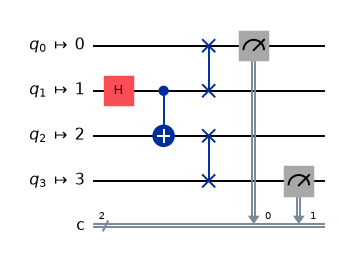

  native gates (what the table counts)


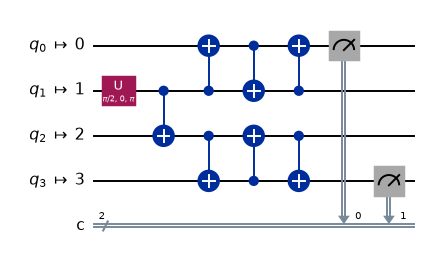

Case 4 - IBM-style today: ports (0, 15)
  routed (SWAPs kept as gates)


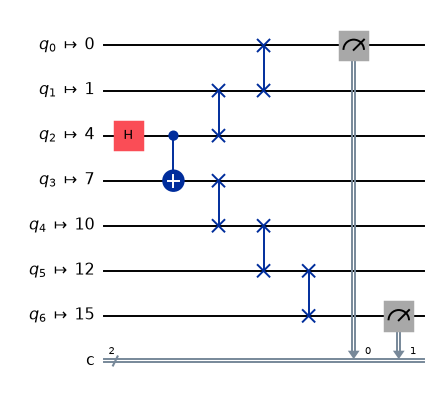

  native gates (what the table counts)


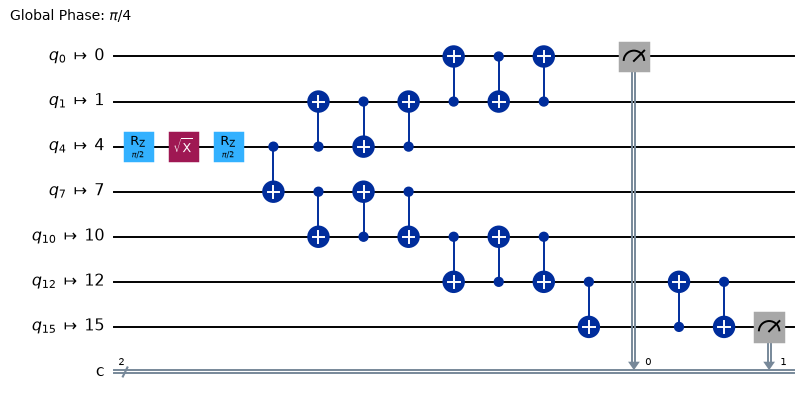

Case 7 - Hyperbolic-inspired: ports (14, 25)
  routed (SWAPs kept as gates)


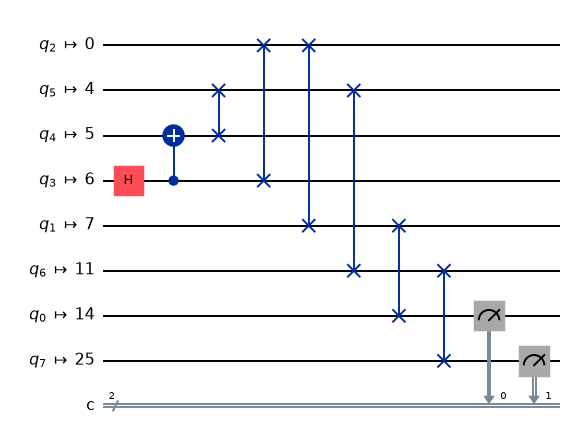

  native gates (what the table counts)


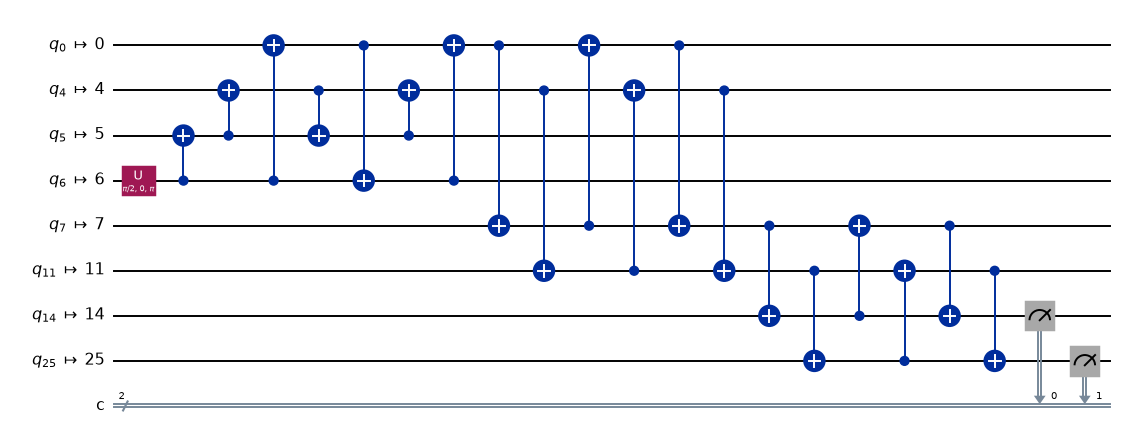

In [10]:
# Draw the compiled ZZ circuits. Idle wires are hidden; wire labels are physical qubit numbers.
for pid, r in LEVEL1.items():
    spec = PROCESSORS[pid]
    print(f"Case {r['case']} - {spec.name}: ports {spec.ports}")
    for label, circ in (("routed (SWAPs kept as gates)", r["runs"]["ZZ"]["routed"]),
                        ("native gates (what the table counts)", r["runs"]["ZZ"]["native"])):
        print("  " + label)
        display(circ.draw("mpl", idle_wires=False, fold=-1, scale=0.7))


## Level 2 — Break it: add noise

**Cases 2, 5, 8:** use each model's official noise assumptions on the Level 1 circuits. Ensure compiled gate names match the noise model, including the IBM backend's native gates.

Report fidelity and a 95% bootstrap confidence interval, resampling each basis independently before combining correlators. Plot fidelity against two-qubit gate count and SWAP overhead. Explain connectivity costs separately from gate-set and noise differences.


In [ ]:
# TODO: Write your solution here.


## Level 3 — Protect it: detect errors

**Cases 3, 6, 9:** implement one justified protection or error-detection check on each model. Explain which faults it detects, which it misses, ancilla placement and routing, and the acceptance rule. Use the same protection procedure and acceptance rule before the basis rotations in all three bases. Do not postselect using final port outcomes.

Compare conditional fidelity and its 95% interval with Level 2. Report acceptance fraction, accepted and discarded shots (per basis), extra gates, depth and physical qubits including ancillas. Handle zero accepted shots explicitly; do not report a fabricated fidelity. Discuss whether any improvement justifies its overhead and lost shots. An accurately analyzed lack of improvement is a valid result.


In [ ]:
# TODO: Write your solution here.


## Nine-case results

Replace every TODO with measured results. Fidelity is conditional on acceptance for Level 3. Report yield and discarded shots for all cases, including cases without postselection. Use the complete compiled ZZ circuit for table costs, following the README common reporting conventions. Provide XX and YY costs separately. Table yield is total accepted shots across all three bases divided by total attempted shots; discarded shots is the sum across bases. Report attempted, accepted and discarded shots per basis below the table. Cases without postselection have yield 1 and zero discarded shots.

| Case | Processor model | Level | F | 95% CI | Depth | Two-qubit gates | SWAPs | Physical qubits | Yield | Discarded shots |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | 1 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 2 | 2016-inspired | 2 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 3 | 2016-inspired | 3 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 4 | IBM-style today | 1 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 5 | IBM-style today | 2 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 6 | IBM-style today | 3 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 7 | Hyperbolic-inspired | 1 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 8 | Hyperbolic-inspired | 2 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| 9 | Hyperbolic-inspired | 3 | TODO | TODO | TODO | TODO | TODO | TODO | TODO | TODO |


In [ ]:
# TODO: Assemble your measured results and comparison plots.


## Scientific interpretation and recommendation

Explain the fidelity changes using compiled operations and noise assumptions. Compare protection overhead and yield across models. State the limits of conclusions drawn from finite graphs and different noise models. Recommend one hardware or software design choice for future cloud systems, supported by your results.

TODO: Write your interpretation and recommendation.

## Optional extensions — Levels 4–5

Keep alternative models, optimization studies, scaling studies and real QPU results separate from the nine official cases.

TODO (optional).

## Submission checklist

- Complete all nine cases with reproducible code and saved outputs.
- Include the three labeled coupling graphs, fixed ports and transpiled circuits.
- Report fidelity with uncertainty, circuit costs, physical qubits and postselection statistics.
- Record assumptions, package versions, shots, seeds and compilation/bootstrap settings.
- Include scientific interpretation and an evidence-backed design recommendation.
- Restart the kernel and run all cells from top to bottom before saving.
- Commit and push the notebook, supporting files and any dependency changes to your fork.
- Open a pull request to the main challenge repository by Sunday 4:00 PM, titled `Submission: <team name>`. Include team members, the notebook path, the results commit hash and reproduction steps, following the README submission instructions. Leave it open for organizer review.
